<a href="https://colab.research.google.com/github/ClarenceBallensky/Cookie_Monster/blob/ml%2Fbaseline/attribute_extractor_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports

In [ ]:
import re
import pandas as pd
import numpy as np

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import GroupShuffleSplit

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score

import torch
from torch.utils.data import Dataset
from transformers import DataCollatorWithPadding

from transformers import AutoTokenizer, AutoModelForSequenceClassification

from google.colab import files

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Possible Starting Models
- Model trained specifically on privacy policy language https://huggingface.co/mukund/privbert

This one is probably the best choice as it specifically is trained on privacy policies which is what we will be looking at. Model will have less to learn about our specific data

- Model trained on the broader side of the legal domain https://huggingface.co/nlpaueb/legal-bert-base-uncased
- Model trained on the english language, case sensitive https://huggingface.co/FacebookAI/roberta-base




Model I (YG) will be using to further explore text-classification
- https://huggingface.co/nlpaueb/legal-bert-base-uncased$0


# Model

In [ ]:
training_data = files.upload()
df = pd.read_json("deduped_training_data.json")
print(df.shape)
print(df.columns.tolist())
print(df["category"].nunique())
print(df["category"].value_counts())
df.head()

Saving deduped_training_data.json to deduped_training_data.json
(5880, 8)
['policy_id', 'segment_id', 'annotation_id', 'category', 'purpose', 'does_or_does_not', 'entity', 'text']
5
category
First Party Collection/Use        2561
Third Party Sharing/Collection    2378
User Choice/Control                739
Data Retention                     176
Do Not Track                        26
Name: count, dtype: int64


,policy_id,segment_id,annotation_id,category,purpose,does_or_does_not,entity,text
0,3905,1,20324,First Party Collection/Use,Basic service/feature,Does,None,Information that Sci-News.com May Collect Onli...
1,3905,1,20590,First Party Collection/Use,Unspecified,Does,None,Information that Sci-News.com May Collect Onli...
2,3905,2,20326,Data Retention,Unspecified,None,None,"- if you contact us, we may keep a record of t..."
3,3905,2,20239,First Party Collection/Use,Unspecified,Does,None,"- if you contact us, we may keep a record of t..."
4,3905,3,C2761,First Party Collection/Use,Unspecified,Does,None,- details of your visits to our site including...


### Slight Restructure of the Dataset
Collapsing the dataset into one row per segment, with all its categories in a list. Allows the model to not get confused when training

Removing extra HTML text

In [ ]:
seg = (df.groupby(["policy_id", "segment_id"])
         .agg(text=("text", "first"),
              categories=("category", lambda category_list: sorted(set(category_list)))
              )
         .reset_index())

seg["text"] = seg["text"].apply(lambda t: re.sub(r"<[^>]+>", " ", t))
seg["text"] = seg["text"].str.replace(r"\s+", " ", regex=True).str.strip()
seg["text"].head()

,text
0,Please read this Privacy Policy carefully. You...
1,about this policy reddit is an open platform t...
2,We do take efforts to make sure the platform k...
3,what information we collect registration infor...
4,"Post, Comment and Messaging Data The posts and..."


In [ ]:
# Turning the list of categories into checklist 0/1 - no/yes
mlb = MultiLabelBinarizer()
y_all = mlb.fit_transform(seg["categories"])
NUM_LABELS = len(mlb.classes_)


# Group split by policy_id to avoid data leakage across train & val
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(gss.split(seg, groups=seg["policy_id"]))

train_df = seg.iloc[train_idx].reset_index(drop=True)
val_df = seg.iloc[val_idx].reset_index(drop=True)

y_train = y_all[train_idx]
y_val = y_all[val_idx]

print(f"Total classes ({NUM_LABELS}): {list(mlb.classes_)}")
print(f"Train split: {len(train_df)} segments ({train_df['policy_id'].nunique()} policies)")
print(f"Val split:   {len(val_df)} segments ({val_df['policy_id'].nunique()} policies)")

print(NUM_LABELS, list(mlb.classes_))
print(len(seg), "segments (was", len(df), "rows)")
seg.head()

Total classes (5): ['Data Retention', 'Do Not Track', 'First Party Collection/Use', 'Third Party Sharing/Collection', 'User Choice/Control']
Train split: 1529 segments (69 policies)
Val split:   533 segments (18 policies)
5 ['Data Retention', 'Do Not Track', 'First Party Collection/Use', 'Third Party Sharing/Collection', 'User Choice/Control']
2062 segments (was 5880 rows)


,policy_id,segment_id,text,categories
0,3621,2,Please read this Privacy Policy carefully. You...,[User Choice/Control]
1,3621,3,about this policy reddit is an open platform t...,"[First Party Collection/Use, Third Party Shari..."
2,3621,4,We do take efforts to make sure the platform k...,"[First Party Collection/Use, Third Party Shari..."
3,3621,5,what information we collect registration infor...,"[Data Retention, First Party Collection/Use]"
4,3621,6,"Post, Comment and Messaging Data The posts and...","[Data Retention, First Party Collection/Use, T..."


# Tokenizing the Data

Loading Pre-Trained Model and Tokenizer on Privacy Policy from PrivBERT


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Model Address on HF
MODEL_NAME = "mukund/privbert"

# Downloads Tokenizer PrivBERT was trained with
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels = NUM_LABELS,
    problem_type = "multi_label_classification",
)



config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.04k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: mukund/privbert
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tokenizing our data so the pre-trained model can read it

In [ ]:
MAX_LEN = 512  # PrivBERT's max input length

class PolicyDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        # Tokenize every paragraph up front (one time, not every epoch)
        self.encodings = tokenizer(
            list(texts),
            # cut anything longer than max_len - not necessary now but set as insurance if we load in more data
            truncation=True,
            max_length=max_len,
        )
        self.labels = labels      # the 0/1 checklist from MultiLabelBinarizer

    # Function for how many examples are in the dataset
    def __len__(self):
        return len(self.labels)

    # Return ONE example as tensors
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.float)
        return item


train_ds = PolicyDataset(train_df["text"], y_train, tokenizer)
val_ds   = PolicyDataset(val_df["text"],   y_val,   tokenizer)

# Looking at one example
sample = train_ds[0]
print({k: v.shape for k, v in sample.items()})
print()
print(tokenizer.decode(sample["input_ids"][:30]))   # should read like our text col
print()
print(sample["labels"])                             # e.g. tensor([0., 0., 1., 1., 0.])

# Shows how many lines were truncated (none for now since our segments are all below the 512 max)
lens = [len(ids) for ids in train_ds.encodings["input_ids"]]
print(f"{sum(l == MAX_LEN for l in lens)} of {len(lens)} train segments were truncated")

{'input_ids': torch.Size([54]), 'attention_mask': torch.Size([54]), 'labels': torch.Size([5])}

<s>Information We Collect We may collect personal information about our users in various ways. For example, we may collect information that you provide to us, information

tensor([0., 0., 1., 0., 0.])
0 of 1529 train segments were truncated


## Loading/Padding Data

Sending sets of 16 paragraphs at a time for the model to train with. Padding allows uss to create a set of data that can be set to the model at once instead of training the model on one paragraph at a time. In order to create a tensor, PyTorch requires each row to be of the same length, thus the padding is necessary.

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

# The collator pads every paragraph in a batch to the length of
#   the longest one, this makes set all the same size
collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Data is shuffled every epoch so the model doesn't memorize the order
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=collator)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=collator)

# Printing one batch
batch = next(iter(train_loader))
print({k: v.shape for k, v in batch.items()})
print(len(train_loader), "batches per epoch")

{'input_ids': torch.Size([16, 184]), 'attention_mask': torch.Size([16, 184]), 'labels': torch.Size([16, 5])}
96 batches per epoch


# Training the Model


In [ ]:
import torch.nn as nn
from torch.optim import AdamW

# Move the model onto the GPU (the batches will go there too)
model.to(device)

# Loss function: measures how wrong the model's guesses are
loss_fn = nn.BCEWithLogitsLoss()

# Optimizer: nudges the model's weights to reduce the loss
optimizer = AdamW(model.parameters(), lr=2e-5)

EPOCHS = 3

# Sanity check: run ONE batch through the model, without training
batch = {k: v.to(device) for k, v in batch.items()}

with torch.no_grad():
    outputs = model(input_ids=batch["input_ids"],
                    attention_mask=batch["attention_mask"])
    loss = loss_fn(outputs.logits, batch["labels"])

print(outputs.logits.shape)
print("Current error: ", loss.item())

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

torch.Size([16, 5])
Current error:  0.7039470672607422


Analyzing data


Epoch 1/3 - train loss: 0.3956, val loss: 0.2536
Epoch 2/3 - train loss: 0.2209, val loss: 0.1898
Epoch 3/3 - train loss: 0.1522, val loss: 0.1747


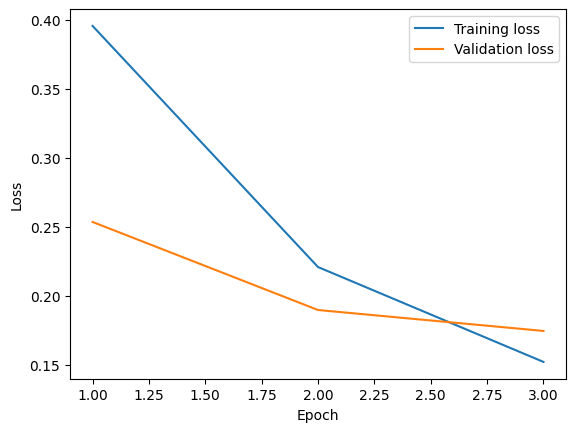

In [ ]:
import matplotlib.pyplot as plt

EPOCHS = 3
train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    # ---- Training ----
    model.train()     # Putting model in training mode
    total_loss = 0
    for batch in train_loader:
        # Move this batch onto the GPU
        batch = {k: v.to(device) for k, v in batch.items()}

        # 1. Clear out the old gradients
        optimizer.zero_grad()

        # 2. Forward pass: the model makes its guesses
        outputs = model(input_ids=batch["input_ids"],
                        attention_mask=batch["attention_mask"])

        # 3. Measure how wrong the guesses were
        loss = loss_fn(outputs.logits, batch["labels"])

        # 4. Backward pass: figure out how to fix each weight
        loss.backward()

        # 5. Update the weights
        optimizer.step()
        total_loss += loss.item()

    train_losses.append(total_loss / len(train_loader))

    # ---- Validation (no learning, just measuring) ----
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            # Move this batch onto the GPU
            batch = {k: v.to(device) for k, v in batch.items()}

            # The model makes its guesses
            outputs = model(input_ids=batch["input_ids"],
                            attention_mask=batch["attention_mask"])

            # Measure how wrong the guesses were
            loss = loss_fn(outputs.logits, batch["labels"])
            total_val_loss += loss.item()

    val_losses.append(total_val_loss / len(val_loader))

    print(f"Epoch {epoch + 1}/{EPOCHS} - train loss: {train_losses[-1]:.4f}, val loss: {val_losses[-1]:.4f}")

# ---- Plot ----
plt.plot(range(1, EPOCHS + 1), train_losses, label="Training loss")
plt.plot(range(1, EPOCHS + 1), val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

model.save_pretrained("/content/drive/MyDrive/privbert_cookie_model")
tokenizer.save_pretrained("/content/drive/MyDrive/privbert_cookie_model")

Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/privbert_cookie_model/tokenizer_config.json',
 '/content/drive/MyDrive/privbert_cookie_model/tokenizer.json')

Report on the model


In [ ]:
from sklearn.metrics import classification_report

model.eval()   # switch out of training mode
all_probs = []
all_labels = []

with torch.no_grad():   # no learning, just measuring
    for batch in val_loader:
        # Move this batch onto the GPU
        batch = {k: v.to(device) for k, v in batch.items()}

        # The model makes its guesses
        outputs = model(input_ids=batch["input_ids"],
                        attention_mask=batch["attention_mask"])

        # Turn raw scores into probabilities between 0 and 1
        probs = torch.sigmoid(outputs.logits)

        # Save the results (moved off the GPU) so we can score them later
        all_probs.append(probs.cpu())
        all_labels.append(batch["labels"].cpu())

# Stack all the batches into one big table
all_probs = torch.cat(all_probs).numpy()
all_labels = torch.cat(all_labels).numpy()

# Probability above 0.5 means "yes, this category applies"
preds = (all_probs > 0.5).astype(int)

# Print precision, recall, and F1 for each category
print(classification_report(all_labels, preds, target_names=mlb.classes_, zero_division=0))

                                precision    recall  f1-score   support

                Data Retention       0.81      0.62      0.70        34
                  Do Not Track       1.00      0.86      0.92         7
    First Party Collection/Use       0.90      0.90      0.90       284
Third Party Sharing/Collection       0.96      0.85      0.91       247
           User Choice/Control       0.84      0.81      0.83       141

                     micro avg       0.91      0.85      0.88       713
                     macro avg       0.90      0.81      0.85       713
                  weighted avg       0.91      0.85      0.88       713
                   samples avg       0.93      0.90      0.89       713



                                precision    recall  f1-score   support

                Data Retention       0.81      0.62      0.70        34
                  Do Not Track       1.00      0.86      0.92         7
    First Party Collection/Use       0.90      0.90      0.90       284
Third Party Sharing/Collection       0.96      0.85      0.91       247
           User Choice/Control       0.84      0.81      0.83       141

                     micro avg       0.91      0.85      0.88       713
                     macro avg       0.90      0.81      0.85       713
                  weighted avg       0.91      0.85      0.88       713
                   samples avg       0.93      0.90      0.89       713

